# 购买概率建模与 Uplift 校准

本文件估计客户在触达与不触达时的购买概率，构造用于客户排序的增量响应分数，并检查该分数是否具有合理的效果幅度。

| 模型 | 训练样本 | 用途 |
|---|---|---|
| Response | 全部训练客户 | 购买倾向基线 |
| m0 | 对照组训练客户 | 不触达时的购买概率 |
| m1 | 触达组训练客户 | 触达时的购买概率 |

T-learner 分数为 `m1(X) − m0(X)`。沿用 HistGradientBoostingClassifier 及原参数；预处理与模型均在训练数据拟合。

**已有结果：** 三个分类器的验证 AUC 约为 0.77，但购买预测能力不能代替效果评价。验证集最高分组预测提升 9.37 个百分点，DR 估计为 5.37；最低分组预测 −1.07，DR 估计为 +2.21，提示效果幅度存在校准问题。负预测不能直接作为个人受损标签。

**评价衔接：** 本文件检查预测与分组效果，下一文件检验固定触达名额下的策略增量价值。分组 DR 评价沿用尚待核实的 `e=0.5` 假设。

2026-10-25 完善复现流程；运行 01 后使用新生成的处理后数据重新训练，沿用原模型和参数。研究设计与限制见 [研究设计说明](docs/research_design.md)，复现方法见 [运行说明](docs/reproducibility.md)。


① 读取划分好的数据

In [1]:
import duckdb
import pandas as pd

train_df = duckdb.sql("""
    SELECT * FROM read_parquet('data/processed/train.parquet')
""").df()

valid_df = duckdb.sql("""
    SELECT * FROM read_parquet('data/processed/validation.parquet')
""").df()

test_df = duckdb.sql("""
    SELECT * FROM read_parquet('data/processed/test.parquet')
""").df()

print("训练集：", train_df.shape)
print("验证集：", valid_df.shape)
print("测试集：", test_df.shape)

训练集： (120023, 17)
验证集： (40008, 17)
测试集： (40008, 17)


② 定义输入特征

In [2]:
numeric_features = [
    "age_clean",
    "age_review_flag",
    "recency_days",
    "txn_count_history",
    "spend_history",
    "avg_transaction_amount",
    "txn_count_30d",
    "spend_30d",
    "zero_amount_txn_count"
]

categorical_features = ["gender"]

feature_columns = numeric_features + categorical_features

X_train = train_df[feature_columns]
y_train = train_df["target"]
t_train = train_df["treatment_flg"]

X_valid = valid_df[feature_columns]

print("训练集输入维度：", X_train.shape)
display(X_train.head())

训练集输入维度： (120023, 10)


,age_clean,age_review_flag,recency_days,txn_count_history,spend_history,avg_transaction_amount,txn_count_30d,spend_30d,zero_amount_txn_count,gender
0,38,0,8,10,3420.68,342.068000,3,1466.75,0,U
1,56,0,12,3,1867.29,622.430000,2,762.09,0,U
2,39,0,14,4,1141.50,285.375000,1,104.80,0,M
3,36,0,11,7,1978.00,282.571429,1,612.29,0,F
4,82,0,9,21,5575.00,265.476190,4,807.00,0,U


③ 定义预处理与模型
数值缺失采用训练数据的中位数填补；性别编码为类别指示变量。每次调用函数都会创建独立的处理流程和模型。

In [3]:
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder
from sklearn.ensemble import HistGradientBoostingClassifier

def make_model():
    preprocessing = ColumnTransformer([
        (
            "numeric",
            SimpleImputer(strategy="median"),
            numeric_features
        ),
        (
            "categorical",
            OneHotEncoder(
                handle_unknown="ignore",
                sparse_output=False
            ),
            categorical_features
        )
    ])

    classifier = HistGradientBoostingClassifier(
        learning_rate=0.05,
        max_iter=150,
        max_leaf_nodes=15,
        min_samples_leaf=100,
        l2_regularization=1.0,
        early_stopping=True,
        random_state=42
    )

    return Pipeline([
        ("preprocessing", preprocessing),
        ("classifier", classifier)
    ])

④ 训练三个分类器
| 模型 | 训练对象 | 用途 |
|---|---|---|
| `response_model` | 全部训练客户 | 预测历史混合触达环境下的购买倾向 |
| `m0` | 对照组训练客户 | 预测未触达情况下的购买概率 |
| `m1` | 触达组训练客户 | 预测触达情况下的购买概率 |

In [4]:
response_model = make_model()
m0 = make_model()
m1 = make_model()

response_model.fit(X_train, y_train)
print("购买概率模型训练完成")

control_mask = t_train.eq(0)
treated_mask = t_train.eq(1)

m0.fit(
    X_train.loc[control_mask],
    y_train.loc[control_mask]
)
print("对照组模型 m0 训练完成")

m1.fit(
    X_train.loc[treated_mask],
    y_train.loc[treated_mask]
)
print("触达组模型 m1 训练完成")

购买概率模型训练完成


对照组模型 m0 训练完成


触达组模型 m1 训练完成


⑤ 在验证集生成预测并检查结果
T-learner 的 uplift 分数为：
$$
\widehat{\tau}(X)=\widehat m_1(X)-\widehat m_0(X)
$$

In [5]:
from sklearn.metrics import roc_auc_score, log_loss

valid_scores = valid_df[
    ["client_id", "treatment_flg", "target"]
].copy()

valid_scores["response_score"] = (
    response_model.predict_proba(X_valid)[:, 1]
)

valid_scores["p0"] = m0.predict_proba(X_valid)[:, 1]
valid_scores["p1"] = m1.predict_proba(X_valid)[:, 1]
valid_scores["uplift_score"] = valid_scores["p1"] - valid_scores["p0"]

# 检查各分类器在相应验证人群上的购买预测表现
evaluation_rows = []

evaluation_groups = [
    ("Response / all", valid_scores, "response_score"),
    (
        "m0 / controls",
        valid_scores.loc[valid_scores["treatment_flg"].eq(0)],
        "p0"
    ),
    (
        "m1 / treated",
        valid_scores.loc[valid_scores["treatment_flg"].eq(1)],
        "p1"
    )
]

for name, data, score in evaluation_groups:
    evaluation_rows.append({
        "model": name,
        "customers": len(data),
        "roc_auc": roc_auc_score(data["target"], data[score]),
        "log_loss": log_loss(data["target"], data[score])
    })

display(pd.DataFrame(evaluation_rows))

display(
    valid_scores["uplift_score"]
    .describe(percentiles=[0.1, 0.5, 0.9])
)

,model,customers,roc_auc,log_loss
0,Response / all,40008,0.773390,0.547176
1,m0 / controls,20011,0.774512,0.552252
2,m1 / treated,19997,0.772045,0.541637


count    40008.000000
mean         0.035311
std          0.038569
min         -0.203704
10%         -0.006001
50%          0.029790
90%          0.085134
max          0.275837
Name: uplift_score, dtype: float64

In [6]:
from IPython.display import display, Markdown

uplift_summary = valid_scores["uplift_score"].describe(percentiles=[0.1, 0.5, 0.9])
display(Markdown(f"""
### 购买预测与 Uplift 分数概况

- 各分类器的 AUC 与 log loss 见上表；评价人群不同，不直接据此排名。
- 平均预测 uplift 为 **{uplift_summary['mean'] * 100:.2f} 个百分点**。
- 第 90 百分位为 **{uplift_summary['90%'] * 100:.2f} 个百分点**。
- 最低预测为 **{uplift_summary['min'] * 100:.2f} 个百分点**。

购买预测性能不能替代处理效应评价；负预测也不能直接证明相应客户会受到营销伤害。以下使用验证集分组效果检查排序与数值校准。
"""))



### 购买预测与 Uplift 分数概况

- 各分类器的 AUC 与 log loss 见上表；评价人群不同，不直接据此排名。
- 平均预测 uplift 为 **3.53 个百分点**。
- 第 90 百分位为 **8.51 个百分点**。
- 最低预测为 **-20.37 个百分点**。

购买预测性能不能替代处理效应评价；负预测也不能直接证明相应客户会受到营销伤害。以下使用验证集分组效果检查排序与数值校准。


## 保存模型、配置与验证集预测


In [7]:
from pathlib import Path
import json
import joblib
import sklearn

# 创建输出目录
model_dir = Path("models")
data_dir = Path("data/processed")
report_dir = Path("reports/tables")

for folder in [model_dir, data_dir, report_dir]:
    folder.mkdir(parents=True, exist_ok=True)

# 1. 保存模型：每个模型都包含已拟合的预处理流程
joblib.dump(response_model, model_dir / "response_model.joblib")
joblib.dump(m0, model_dir / "tlearner_m0.joblib")
joblib.dump(m1, model_dir / "tlearner_m1.joblib")

# 2. 保存特征顺序和基本配置
model_config = {
    "feature_columns": feature_columns,
    "numeric_features": numeric_features,
    "categorical_features": categorical_features,
    "random_state": 42,
    "feature_cutoff": str(train_df["feature_cutoff"].iloc[0]),
    "train_customers": len(train_df),
    "validation_customers": len(valid_df),
    "test_customers": len(test_df),
    "sklearn_version": sklearn.__version__,
    "pandas_version": pd.__version__,
    "duckdb_version": duckdb.__version__,
    "joblib_version": joblib.__version__
}

with (model_dir / "model_config.json").open(
    "w", encoding="utf-8"
) as f:
    json.dump(model_config, f, ensure_ascii=False, indent=2)

# 3. 保存验证集预测，供第三部分读取
with duckdb.connect() as export_con:
    export_con.register("scores_to_save", valid_scores)

    export_con.execute("""
        COPY scores_to_save
        TO 'data/processed/validation_scores.parquet'
        (FORMAT PARQUET)
    """)

# 4. 保存本次验证指标
pd.DataFrame(evaluation_rows).to_csv(
    report_dir / "validation_prediction_metrics.csv",
    index=False
)

valid_scores["uplift_score"].describe(
    percentiles=[0.1, 0.5, 0.9]
).to_csv(
    report_dir / "validation_uplift_summary.csv"
)

print("模型、配置、验证集预测和指标已保存。")

模型、配置、验证集预测和指标已保存。


## 验证集 Uplift 分组校准

沿用假设处理概率 e = 0.5；直接使用本次生成的验证集预测，避免重复读取旧文件。分组不使用处理标记或购买结果。


In [8]:
import duckdb
import numpy as np
import pandas as pd

# 使用本次验证集预测
calibration = valid_scores.copy()

required_columns = [
    "client_id",
    "treatment_flg",
    "target",
    "p0",
    "p1",
    "uplift_score"
]

assert calibration[required_columns].notna().all().all()
assert calibration["client_id"].is_unique
assert calibration["treatment_flg"].isin([0, 1]).all()
assert calibration["target"].isin([0, 1]).all()

# 仍沿用当前待核实的处理概率假设
e = 0.5

t = calibration["treatment_flg"].to_numpy()
y = calibration["target"].to_numpy()
p0 = calibration["p0"].to_numpy()
p1 = calibration["p1"].to_numpy()

calibration["dr_score"] = (
    p1 - p0
    + t / e * (y - p1)
    - (1 - t) / (1 - e) * (y - p0)
)

# 分组只依据预测分数；同分时按客户 ID 确定顺序
calibration = calibration.sort_values(
    ["uplift_score", "client_id"]
).reset_index(drop=True)

calibration["uplift_group"] = pd.qcut(
    calibration["uplift_score"].rank(method="first"),
    q=5,
    labels=["Q1_lowest", "Q2", "Q3", "Q4", "Q5_highest"]
)

rows = []

for group, frame in calibration.groupby(
    "uplift_group",
    observed=True,
    sort=True
):
    n_group = len(frame)
    dr_mean = frame["dr_score"].mean()
    dr_se = frame["dr_score"].std(ddof=1) / np.sqrt(n_group)

    rows.append({
        "group": group,
        "customers": n_group,
        "control_n": int(frame["treatment_flg"].eq(0).sum()),
        "treated_n": int(frame["treatment_flg"].eq(1).sum()),
        "predicted_uplift_pp": frame["uplift_score"].mean() * 100,
        "dr_effect_pp": dr_mean * 100,
        "ci_low_pp": (dr_mean - 1.96 * dr_se) * 100,
        "ci_high_pp": (dr_mean + 1.96 * dr_se) * 100
    })

uplift_calibration = pd.DataFrame(rows)

print("以下效果及区间的单位均为：百分点")
display(uplift_calibration.round(2))

以下效果及区间的单位均为：百分点


,group,customers,control_n,treated_n,predicted_uplift_pp,dr_effect_pp,ci_low_pp,ci_high_pp
0,Q1_lowest,8002,4024,3978,-1.07,2.21,0.42,4.00
1,Q2,8001,3949,4052,1.33,2.37,0.66,4.09
2,Q3,8002,3979,4023,2.99,1.68,-0.17,3.54
3,Q4,8001,4004,3997,5.03,4.33,2.36,6.30
4,Q5_highest,8002,4055,3947,9.37,5.37,3.29,7.44


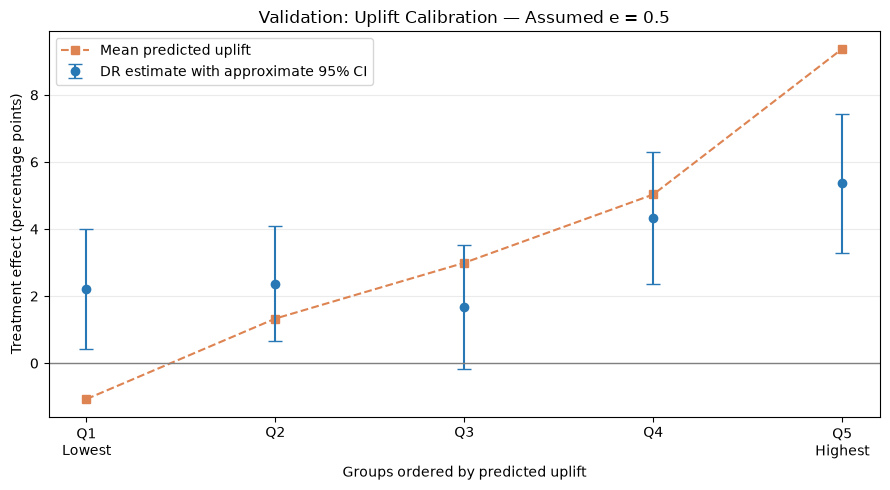

In [9]:
import matplotlib.pyplot as plt
import numpy as np

plot_data = uplift_calibration.copy()
x = np.arange(len(plot_data))

fig, ax = plt.subplots(figsize=(9, 5))

# 模型预测的组平均效果
ax.plot(
    x,
    plot_data["predicted_uplift_pp"],
    marker="s",
    linestyle="--",
    color="#DD8452",
    label="Mean predicted uplift"
)

# DR 估计的组平均效果及近似置信区间
ax.errorbar(
    x,
    plot_data["dr_effect_pp"],
    yerr=np.vstack([
        plot_data["dr_effect_pp"] - plot_data["ci_low_pp"],
        plot_data["ci_high_pp"] - plot_data["dr_effect_pp"]
    ]),
    fmt="o",
    capsize=5,
    color="#2878B5",
    label="DR estimate with approximate 95% CI"
)

ax.axhline(0, color="gray", linewidth=1)
ax.set_xticks(
    x,
    ["Q1\nLowest", "Q2", "Q3", "Q4", "Q5\nHighest"]
)
ax.set_xlabel("Groups ordered by predicted uplift")
ax.set_ylabel("Treatment effect (percentage points)")
ax.set_title("Validation: Uplift Calibration — Assumed e = 0.5")
ax.legend()
ax.grid(axis="y", alpha=0.25)

plt.tight_layout()
plt.show()

In [10]:
low = uplift_calibration.iloc[0]
high = uplift_calibration.iloc[-1]

display(Markdown(f"""
### 分组校准诊断

最高分组：平均预测为 **{high['predicted_uplift_pp']:.2f} 个百分点**，DR 平均效果估计为 **{high['dr_effect_pp']:.2f}**，近似 95% CI 为 **[{high['ci_low_pp']:.2f}, {high['ci_high_pp']:.2f}]**。

最低分组：平均预测为 **{low['predicted_uplift_pp']:.2f} 个百分点**，DR 平均效果估计为 **{low['dr_effect_pp']:.2f}**，近似 95% CI 为 **[{low['ci_low_pp']:.2f}, {low['ci_high_pp']:.2f}]**。

这张表分别检查排序和数值校准：高分是否对应更高的估计效果，以及预测幅度是否接近分组效果。不能仅凭各组区间是否重叠判断组间差异，也不能从组平均效果推断个人效果。负预测不能直接用作“受损客户”的标签。

本节是验证集探索分析。区间条件于已训练模型，依赖处理概率与因果识别假设，不包含重新训练的不确定性，也不是多个组的同时置信区间。
"""))



### 分组校准诊断

最高分组：平均预测为 **9.37 个百分点**，DR 平均效果估计为 **5.37**，近似 95% CI 为 **[3.29, 7.44]**。

最低分组：平均预测为 **-1.07 个百分点**，DR 平均效果估计为 **2.21**，近似 95% CI 为 **[0.42, 4.00]**。

这张表分别检查排序和数值校准：高分是否对应更高的估计效果，以及预测幅度是否接近分组效果。不能仅凭各组区间是否重叠判断组间差异，也不能从组平均效果推断个人效果。负预测不能直接用作“受损客户”的标签。

本节是验证集探索分析。区间条件于已训练模型，依赖处理概率与因果识别假设，不包含重新训练的不确定性，也不是多个组的同时置信区间。
